# 3. EDA & Business Analysis

## 3.1 Loading Processed Data

In [113]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import seaborn as sns

In [4]:
DATA_DIR = Path("../data/processed")

In [8]:
csv_files = list(DATA_DIR.glob("*.csv"))

In [15]:
for file in csv_files:
    size = ((file.stat().st_size) / (1024 * 1024))
    print(f"{file.name} | {size:.2f}MB")

item_masters.csv | 37.87MB
order_masters.csv | 27.61MB


In [17]:
item_masters = pd.read_csv(DATA_DIR / "item_masters.csv")
order_masters = pd.read_csv(DATA_DIR / "order_masters.csv")

In [18]:
item_masters.head(5)

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,product_category_name,product_name_lenght,product_description_lenght,...,seller_zip_code_prefix,seller_city,seller_state,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,cool_stuff,58.0,598.0,...,27277,volta redonda,SP,3ce436f183e68e07877b285a838db11a,delivered,2017-09-13 08:59:02,2017-09-13 09:45:35,2017-09-19 18:34:16,2017-09-20 23:43:48,2017-09-29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,pet_shop,56.0,239.0,...,3471,sao paulo,SP,f6dd3ec061db4e3987629fe6b26e5cce,delivered,2017-04-26 10:53:06,2017-04-26 11:05:13,2017-05-04 14:35:00,2017-05-12 16:04:24,2017-05-15
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,moveis_decoracao,59.0,695.0,...,37564,borda da mata,MG,6489ae5e4333f3693df5ad4372dab6d3,delivered,2018-01-14 14:33:31,2018-01-14 14:48:30,2018-01-16 12:36:48,2018-01-22 13:19:16,2018-02-05
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,perfumaria,42.0,480.0,...,14403,franca,SP,d4eb9395c8c0431ee92fce09860c5a06,delivered,2018-08-08 10:00:35,2018-08-08 10:10:18,2018-08-10 13:28:00,2018-08-14 13:32:39,2018-08-20
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,ferramentas_jardim,59.0,409.0,...,87900,loanda,PR,58dbd0b2d70206bf40e62cd34e84d795,delivered,2017-02-04 13:57:51,2017-02-04 14:10:13,2017-02-16 09:46:09,2017-03-01 16:42:31,2017-03-17


In [19]:
order_masters.head(5)

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,total_items,total_price,total_freight,total_payment_value,payment_installments,payment_type,review_score,review_comment_message
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,7c396fd4830fd04220f754e42b4e5bff,3149,sao paulo,SP,1.0,29.99,8.72,38.71,1.0,credit_card,4.0,"Não testei o produto ainda, mas ele veio corre..."
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,af07308b275d755c9edb36a90c618231,47813,barreiras,BA,1.0,118.70,22.76,141.46,1.0,boleto,4.0,Muito bom o produto.
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,3a653a41f6f9fc3d2a113cf8398680e8,75265,vianopolis,GO,1.0,159.90,19.22,179.12,3.0,credit_card,5.0,NaN
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,7c142cf63193a1473d2e66489a9ae977,59296,sao goncalo do amarante,RN,1.0,45.00,27.20,72.20,1.0,credit_card,5.0,O produto foi exatamente o que eu esperava e e...
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,72632f0f9dd73dfee390c9b22eb56dd6,9195,santo andre,SP,1.0,19.90,8.72,28.62,1.0,credit_card,5.0,NaN


In [26]:
columns = ["shipping_limit_date", "order_purchase_timestamp",
             "order_approved_at", "order_delivered_carrier_date",
             "order_delivered_customer_date", "order_estimated_delivery_date"]
for col in columns:
    item_masters[col] = pd.to_datetime(item_masters[col])

In [28]:
item_masters.info()

<class 'pandas.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 26 columns):
 #   Column                         Non-Null Count   Dtype         
---  ------                         --------------   -----         
 0   order_id                       112650 non-null  str           
 1   order_item_id                  112650 non-null  int64         
 2   product_id                     112650 non-null  str           
 3   seller_id                      112650 non-null  str           
 4   shipping_limit_date            112650 non-null  datetime64[us]
 5   price                          112650 non-null  float64       
 6   freight_value                  112650 non-null  float64       
 7   product_category_name          112650 non-null  str           
 8   product_name_lenght            112650 non-null  float64       
 9   product_description_lenght     112650 non-null  float64       
 10  product_photos_qty             112650 non-null  float64       
 11  product_wei

In [30]:
columns = ["order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
           "order_delivered_customer_date", "order_estimated_delivery_date"]
for col in columns:
    order_masters[col] = pd.to_datetime(order_masters[col])

In [31]:
order_masters.info()

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 20 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_id                       99441 non-null  str           
 1   customer_id                    99441 non-null  str           
 2   order_status                   99441 non-null  str           
 3   order_purchase_timestamp       99441 non-null  datetime64[us]
 4   order_approved_at              99281 non-null  datetime64[us]
 5   order_delivered_carrier_date   97658 non-null  datetime64[us]
 6   order_delivered_customer_date  96476 non-null  datetime64[us]
 7   order_estimated_delivery_date  99441 non-null  datetime64[us]
 8   customer_unique_id             99441 non-null  str           
 9   customer_zip_code_prefix       99441 non-null  int64         
 10  customer_city                  99441 non-null  str           
 11  customer_state            

## 3.2 Feature Engineering

In [68]:
order_masters["delivery_time_days"] = round((order_masters[
    "order_delivered_customer_date"] - order_masters[
        "order_purchase_timestamp"]).dt.total_seconds() / 86400, 2)

In [69]:
order_masters["delivery_delay_days"] = round((order_masters[
    "order_delivered_customer_date"] - order_masters[
        "order_estimated_delivery_date"]).dt.total_seconds() / 86400, 2)

In [70]:
order_masters["is_late"] = order_masters["delivery_delay_days"] > 0

In [71]:
order_masters["purchase_month"] = order_masters["order_purchase_timestamp"].dt.to_period("M")

In [72]:
order_masters[["delivery_time_days", "delivery_delay_days", "is_late", "purchase_month"]].head(5)

,delivery_time_days,delivery_delay_days,is_late,purchase_month
0,8.44,-7.11,False,2017-10
1,13.78,-5.36,False,2018-07
2,9.39,-17.25,False,2018-08
3,13.21,-12.98,False,2017-11
4,2.87,-9.24,False,2018-02


## 3.3 Business Question 1: Logistics & Customer Satisfaction

In [73]:
delivered = order_masters[order_masters["order_status"] == "delivered"].copy()

In [77]:
delivered["is_late"].value_counts(normalize=True) * 100

is_late
False    91.894525
True      8.105475
Name: proportion, dtype: float64

In [81]:
delivered.groupby("is_late", as_index=False).agg(
    order_counts=("order_id", "count"),
    mean_review_score=("review_score", "mean"),
    median_review_score=("review_score", "median")
)

,is_late,order_counts,mean_review_score,median_review_score
0,False,88658,4.294313,5.0
1,True,7820,2.565121,2.0


## 3.3.1 Visualizing Delay Severity vs. Review Score

In [83]:
delivered["delay_bucket"] = pd.cut(delivered["delivery_delay_days"], bins=[-np.inf, 0, 3, 7, np.inf],
                                  labels=["Early /On Time", "1-3 Days Late",
                                          "4-7 Days Late", "7+ Days Late"])

In [88]:
delay_impact = delivered.groupby("delay_bucket", observed=False).agg(
    order_count=("order_id", "count"),
    avg_review=("review_score", "mean")
)
delay_impact

,order_count,avg_review
delay_bucket,,
Early /On Time,88650,4.294295
1-3 Days Late,2660,3.764427
4-7 Days Late,1819,2.316695
7+ Days Late,3341,1.728140


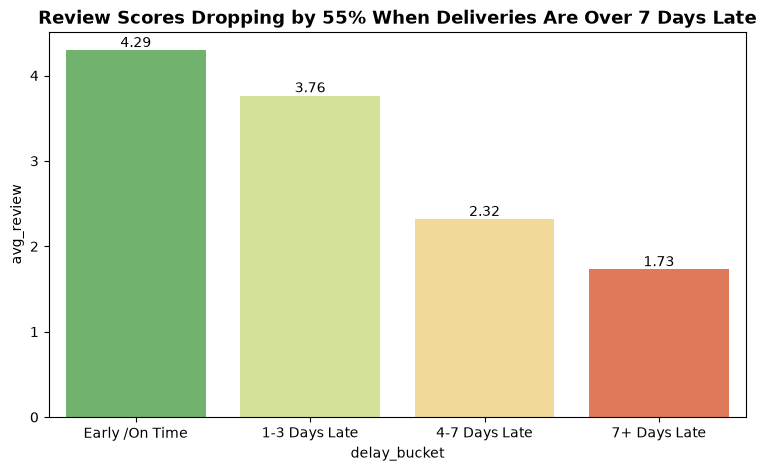

In [99]:
fig, ax = plt.subplots(figsize=(9, 5))

sns.barplot(data=delay_impact, x="delay_bucket", y="avg_review",
           ax=ax, palette="RdYlGn_r", legend=False, hue="delay_bucket", dodge=False)
ax.set_title("Review Scores Dropping by 55% When Deliveries Are Over 7 Days Late",
            fontsize=13, fontweight="bold")

ax.bar_label(ax.containers[0], fmt="%.2f")
ax.bar_label(ax.containers[1], fmt="%.2f")
ax.bar_label(ax.containers[2], fmt="%.2f")
ax.bar_label(ax.containers[3], fmt="%.2f")

fig.savefig("../reports/delivery_delay_vs_review_score.png", dpi=300, bbox_inches="tight")

plt.show()

## 3.4 Business Question 2: Top Revenue Categories & Freight Burden

In [105]:
delivered_items = item_masters[item_masters["order_status"] == "delivered"].copy()

In [106]:
delivered_items.head(10)

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,product_category_name,product_name_lenght,product_description_lenght,...,seller_zip_code_prefix,seller_city,seller_state,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,cool_stuff,58.0,598.0,...,27277,volta redonda,SP,3ce436f183e68e07877b285a838db11a,delivered,2017-09-13 08:59:02,2017-09-13 09:45:35,2017-09-19 18:34:16,2017-09-20 23:43:48,2017-09-29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,pet_shop,56.0,239.0,...,3471,sao paulo,SP,f6dd3ec061db4e3987629fe6b26e5cce,delivered,2017-04-26 10:53:06,2017-04-26 11:05:13,2017-05-04 14:35:00,2017-05-12 16:04:24,2017-05-15
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,moveis_decoracao,59.0,695.0,...,37564,borda da mata,MG,6489ae5e4333f3693df5ad4372dab6d3,delivered,2018-01-14 14:33:31,2018-01-14 14:48:30,2018-01-16 12:36:48,2018-01-22 13:19:16,2018-02-05
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,perfumaria,42.0,480.0,...,14403,franca,SP,d4eb9395c8c0431ee92fce09860c5a06,delivered,2018-08-08 10:00:35,2018-08-08 10:10:18,2018-08-10 13:28:00,2018-08-14 13:32:39,2018-08-20
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,ferramentas_jardim,59.0,409.0,...,87900,loanda,PR,58dbd0b2d70206bf40e62cd34e84d795,delivered,2017-02-04 13:57:51,2017-02-04 14:10:13,2017-02-16 09:46:09,2017-03-01 16:42:31,2017-03-17
5,00048cc3ae777c65dbb7d2a0634bc1ea,1,ef92defde845ab8450f9d70c526ef70f,6426d21aca402a131fc0a5d0960a3c90,2017-05-23 03:55:27,21.90,12.69,utilidades_domesticas,36.0,558.0,...,14091,ribeirao preto,SP,816cbea969fe5b689b39cfc97a506742,delivered,2017-05-15 21:42:34,2017-05-17 03:55:27,2017-05-17 11:05:55,2017-05-22 13:44:35,2017-06-06
6,00054e8431b9d7675808bcb819fb4a32,1,8d4f2bb7e93e6710a28f34fa83ee7d28,7040e82f899a04d1b434b795a43b4617,2017-12-14 12:10:31,19.90,11.85,telefonia,52.0,815.0,...,1026,sao paulo,SP,32e2e6ab09e778d99bf2e0ecd4898718,delivered,2017-12-10 11:53:48,2017-12-10 12:10:31,2017-12-12 01:07:48,2017-12-18 22:03:38,2018-01-04
7,000576fe39319847cbb9d288c5617fa6,1,557d850972a7d6f792fd18ae1400d9b6,5996cddab893a4652a15592fb58ab8db,2018-07-10 12:30:45,810.00,70.75,ferramentas_jardim,39.0,1310.0,...,19010,presidente prudente,SP,9ed5e522dd9dd85b4af4a077526d8117,delivered,2018-07-04 12:08:27,2018-07-05 16:35:48,2018-07-05 12:15:00,2018-07-09 14:04:07,2018-07-25
8,0005a1a1728c9d785b8e2b08b904576c,1,310ae3c140ff94b03219ad0adc3c778f,a416b6a846a11724393025641d4edd5e,2018-03-26 18:31:29,145.95,11.65,beleza_saude,59.0,493.0,...,3702,sao paulo,SP,16150771dfd4776261284213b89c304e,delivered,2018-03-19 18:40:33,2018-03-20 18:35:21,2018-03-28 00:37:42,2018-03-29 18:17:31,2018-03-29
9,0005f50442cb953dcd1d21e1fb923495,1,4535b0e1091c278dfd193e5a1d63b39f,ba143b05f0110f0dc71ad71b4466ce92,2018-07-06 14:10:56,53.99,11.40,livros_tecnicos,52.0,1192.0,...,2274,sao paulo,SP,351d3cb2cee3c7fd0af6616c82df21d3,delivered,2018-07-02 13:59:39,2018-07-02 14:10:56,2018-07-03 14:25:00,2018-07-04 17:28:31,2018-07-23


In [108]:
category_perf = delivered_items.groupby("product_category_name_english", as_index=False).agg(
    total_orders=("order_id", "nunique"),
    total_revenue=("price", "sum"),
    total_freight=("freight_value", "sum"),
    avg_price=("price", "mean")
)

In [109]:
category_perf["freight_pct"] = (category_perf["total_freight"] / (
    category_perf["total_revenue"] + category_perf["total_freight"]
)) * 100

In [111]:
category_perf.sort_values(by="total_revenue", ascending=False).head(10)

,product_category_name_english,total_orders,total_revenue,total_freight,avg_price,freight_pct
43,health_beauty,8647,1233131.72,178957.81,130.283330,12.673262
73,watches_gifts,5495,1166176.98,98156.14,199.040276,7.763471
7,bed_bath_table,9272,1023434.76,201774.50,93.438762,16.468575
67,sports_leisure,7530,954852.55,163404.36,113.254958,14.612417
15,computers_accessories,6530,888724.61,143999.16,116.264339,13.943628
39,furniture_decor,6307,711927.69,168402.23,87.246040,19.129445
49,housewares,5743,615628.69,142763.56,90.600249,18.824501
20,cool_stuff,3559,610204.10,81476.79,164.121598,11.779535
5,auto,3810,578966.65,90488.10,139.847017,13.516687
71,toys,3804,471286.48,75774.58,116.944536,13.851211


## 3.4.1 Visualizing Top 10 Revenue Categories

In [114]:
top_10_categories = category_perf.sort_values(by="total_revenue", ascending=False).head(10)

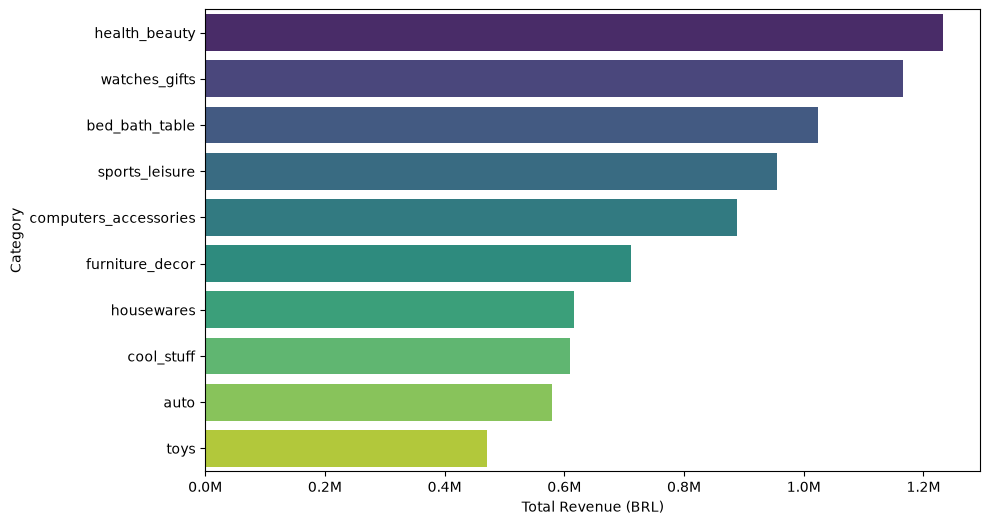

In [122]:
fig, ax = plt.subplots(figsize=(10, 6))

ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"{x/1e6:.1f}M"))

ax.set_xlabel("Total Revenue (BRL)")
ax.set_ylabel("Category")

sns.barplot(data=top_10_categories, x="total_revenue", y="product_category_name_english", hue="product_category_name_english",
           dodge=False, legend=False, palette="viridis", ax=ax)

fig.savefig("../reports/top_10_revenue_categories.png", dpi=300, bbox_inches="tight")

## 3.5 Business Question 3: Monthly Revenue Growth & Seasonality

In [124]:
monthly_rev = delivered.groupby("purchase_month", as_index=False).agg(
    total_orders=("order_id", "count"),
    total_revenue=("total_price", "sum"),
    avg_order_value=("total_price", "mean")
)

In [126]:
monthly_rev["purchase_month"] = monthly_rev["purchase_month"].astype("str")

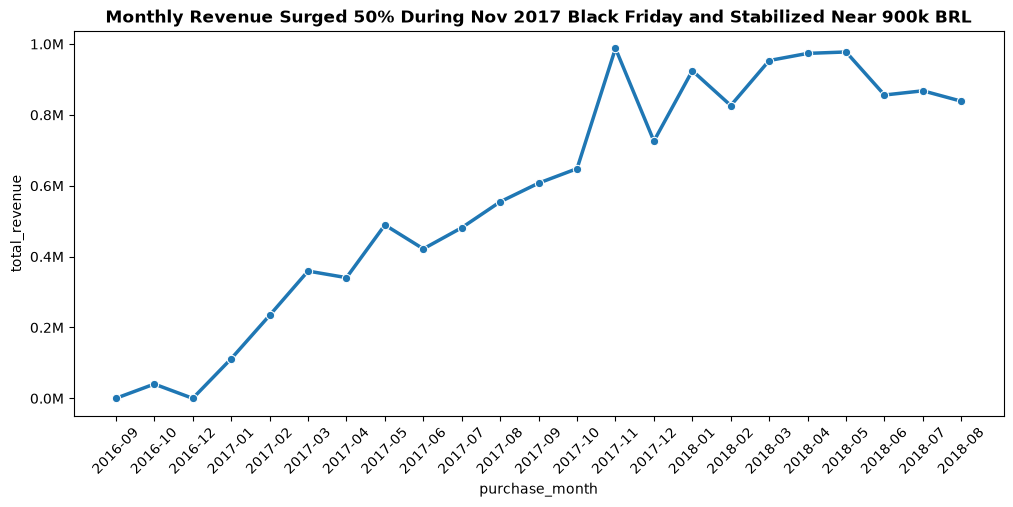

In [131]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.yaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"{x/1e6:.1f}M"))

ax.set_title("Monthly Revenue Surged 50% During Nov 2017 Black Friday and Stabilized Near 900k BRL",
            fontsize=12, fontweight="bold")

ax.tick_params(axis="x", rotation=45)

sns.lineplot(data=monthly_rev, x="purchase_month", y="total_revenue",
            marker="o", linewidth=2.5, ax=ax)

fig.savefig("../reports/monthly_revenue_trend.png", dpi=300, bbox_inches="tight")

## 3.6 Executive Summary & Business Recommendations

### Key Findings
1. **Logistics Reliability Drives Customer Satisfaction (3-Day Grace Window):**
   * Across **96,478 delivered orders**, **91.9%** arrived on time or early (`4.29` average rating; `5.0` median), while **8.1%** arrived late (`2.57` average rating; `2.0` median).
   * Customer ratings remain relatively resilient during minor delays of **1–3 days late** (`3.76` stars), but collapse past the 3-day mark—dropping to **`2.32` stars** at **4–7 days late** and **`1.73` stars** at **7+ days late** (a **60% drop** from on-time orders).

2. **Category Revenue Leaders vs. Freight Cost Burden:**
   * **Health & Beauty** (`1.23M BRL`, `8,647` orders) and **Watches & Gifts** (`1.17M BRL`, `5,495` orders) lead platform revenue, while **Bed, Bath & Table** leads order volume (`9,272` orders, `1.02M BRL`).
   * **Watches & Gifts** acts as a high-margin hero category with the highest average item price (`199.04 BRL`) and lowest shipping burden (**`7.76%`** freight-to-total-spend ratio).
   * In contrast, bulky home categories like **Furniture & Decor** (**`19.13%`**) and **Housewares** (**`18.82%`**) lose nearly **19%** of customer spend to shipping costs.

3. **Rapid Growth & Q4 Black Friday Seasonality:**
   * Following a soft-launch ramp-up in late 2016 (`2016-09` to `2016-12`), monthly revenue grew steadily across 2017 from ~`110K BRL` (`2017-01`) to ~`650K BRL` (`2017-10`).
   * Revenue surged nearly **50% month-over-month** during **November 2017 (Black Friday)** to a dataset peak of `~987K BRL`, then stabilized at a sustained run rate of `~850K–980K BRL` /month throughout 2018.

---

### Actionable Business Recommendations
* **Enforce a 3-Day Delay Intervention SLA:** Trigger automated logistics alerts and proactive customer updates once an order reaches **+2 days** past its estimated delivery date, preventing orders from crossing into the critical 4+ day cliff where ratings fall below 2.4 stars.
* **Optimize Category Ad Spend & Regional Shipping:** Increase marketing spend on high-ticket, low-freight categories (`watches_gifts`, `health_beauty`), while negotiating regional carrier discounts or multi-item shipping bundles for heavy categories (`furniture_decor`, `housewares`) to reduce checkout friction.
* **Pre-Scale Carrier Capacity Before Q4:** Begin seller inventory onboarding and third-party carrier capacity lock-ins by **September** each year to absorb Q4 Black Friday volume surges without triggering late-delivery review penalties.